### Exploring the Imperviousness dataset and merging it with the urban atlas 2021

In [16]:
import rasterio
import pandas as pd

In [2]:
# Define the file path
imperviousness_path = "satellite_data/imperv_berlin_2024.tif"

# Open the raster
imperviousness = rasterio.open(imperviousness_path)

In [ ]:
# Inspect raster metadata
print("CRS:", imperviousness.crs) #coordinates reference system
print("Bounds:", imperviousness.bounds) #geographic extent covered by the raster
print("Width:", imperviousness.width) #number of pixels horizontally
print("Height:", imperviousness.height) #number of pixels vertically
print("Number of bands:", imperviousness.count) #number of raster layers
print("Data type:", imperviousness.dtypes) #how pixel values are stored
print("NoData value:", imperviousness.nodata) #how missing or unavailable pixels are represented
print("Resolution:", imperviousness.res) #ground dimensions represented by each pixel

CRS: EPSG:3035
Bounds: BoundingBox(left=4500000.0, bottom=3200000.0, right=4600000.0, top=3300000.0)
Width: 10000
Height: 10000
Number of bands: 1
Data type: ('uint8',)
NoData value: None
Resolution: (10.0, 10.0)


In [4]:
# Read the first raster band
imperviousness_array = imperviousness.read(1, masked=True)

# Inspect the pixel values
print("Array shape:", imperviousness_array.shape)
print("Minimum:", imperviousness_array.min())
print("Maximum:", imperviousness_array.max())
print("Mean:", imperviousness_array.mean())
print("Unique values (first 20):", 
      sorted(set(imperviousness_array.compressed()))[:20])

Array shape: (10000, 10000)
Minimum: 0
Maximum: 100
Mean: 6.13880749
Unique values (first 20): [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11), np.uint8(12), np.uint8(13), np.uint8(14), np.uint8(15), np.uint8(16), np.uint8(17), np.uint8(18), np.uint8(19)]


Metadata explained:

Property    Your result Interpretation

CRS EPSG:3035   European projected coordinate system

Bounds  4,500,000–4,600,000 / 3,200,000–3,300,000   A 100 × 100 km raster tile

Width   10,000  10,000 pixels horizontally

Height  10,000  10,000 pixels vertically

Bands   1   One raster layer

Data type   uint8   Unsigned 8-bit integers

NoData  None    No explicit NoData value declared in the raster metadata

Resolution  10 × 10 m   Each pixel represents 100 m²

Minimum / Maximum   0 / 100 Values are within a 0–100 range

Mean    6.14    Mean across the entire raster array, not specifically Berlin

In [ ]:
# Inspect additional raster metadata
print("Dataset tags:", imperviousness.tags())
print("Band 1 tags:", imperviousness.tags(1))
print("Color interpretation:", imperviousness.colorinterp)
print("Mask flags:", imperviousness.mask_flag_enums)

Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Color interpretation: (<ColorInterp.palette: 2>,)
Mask flags: ([<MaskFlags.all_valid: 1>],)


In [ ]:
import geopandas as gpd

lor_boundaries = gpd.read_file("satellite_data/berlin_lor_2021.geojson")

# Reproject LOR boundaries to EPSG:25833
lor_metric = lor_boundaries.to_crs(epsg=25833)

In [10]:
# Reproject LOR boundaries to the raster CRS
lor_raster_crs = lor_metric.to_crs(
    imperviousness.crs
)

# Compare geographic bounds
print("Raster bounds:")
print(imperviousness.bounds)

print("\nLOR bounds in raster CRS:")
print(lor_raster_crs.total_bounds)

Raster bounds:
BoundingBox(left=4500000.0, bottom=3200000.0, right=4600000.0, top=3300000.0)

LOR bounds in raster CRS:
[4531042.78524706 3253863.72074189 4576654.31977647 3290794.75294586]


In [ ]:
# Inspect the raster colour palette
color_table = imperviousness.colormap(1)

print("Number of palette entries:", len(color_table))

# Display the first 20 entries
for value, color in list(color_table.items())[:20]:
    print(value, color)

#inspecting the imperviousness profile
print(imperviousness.profile)

#the colour palette is for visualisation; the actual measurements are stored as pixel values in the raster band.

Number of palette entries: 256
0 (240, 240, 240, 255)
1 (255, 237, 195, 255)
2 (253, 232, 190, 255)
3 (251, 227, 186, 255)
4 (250, 222, 181, 255)
5 (248, 217, 177, 255)
6 (246, 213, 172, 255)
7 (244, 208, 168, 255)
8 (242, 203, 164, 255)
9 (241, 199, 160, 255)
10 (239, 194, 156, 255)
11 (237, 190, 152, 255)
12 (235, 186, 148, 255)
13 (234, 182, 144, 255)
14 (232, 178, 141, 255)
15 (230, 174, 137, 255)
16 (228, 170, 134, 255)
17 (227, 166, 130, 255)
18 (225, 162, 127, 255)
19 (223, 158, 123, 255)
{'driver': 'GTiff', 'dtype': 'uint8', 'nodata': None, 'width': 10000, 'height': 10000, 'count': 1, 'crs': CRS.from_wkt('PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARA

In [17]:
import numpy as np

# Count occurrences of each pixel value
values, counts = np.unique(
    imperviousness_array.compressed(),
    return_counts=True
)

# Create a frequency table
pixel_frequency = pd.DataFrame({
    "imperviousness_value": values,
    "pixel_count": counts
})

# Display selected information
print(pixel_frequency.head(15))
print("\nHighest values:")
print(pixel_frequency.tail(10))

print("\nTotal pixels:", counts.sum())
print("Pixels with value 0:", counts[values == 0].sum())
print("Pixels with value 255:", counts[values == 255].sum())

    imperviousness_value  pixel_count
0                      0     90186148
1                      1        19094
2                      2        17896
3                      3        17410
4                      4        16601
5                      5        16183
6                      6        15722
7                      7        15620
8                      8        14852
9                      9        14751
10                    10        14521
11                    11        14617
12                    12        14697
13                    13        14538
14                    14        15198

Highest values:
     imperviousness_value  pixel_count
91                     91        87470
92                     92        87522
93                     93        86746
94                     94        85261
95                     95        84079
96                     96        82712
97                     97        80612
98                     98        77456
99                     9

In [18]:
from rasterio.mask import mask
from shapely.geometry import mapping

In [19]:
# Select one neighbourhood
tiergarten = lor_raster_crs[
    lor_raster_crs["bzr_name"] == "Tiergarten Süd"
]

# Extract its geometry
tiergarten_geometry = tiergarten.geometry.iloc[0]

In [20]:
# Extract raster pixels inside the neighbourhood
out_image, out_transform = mask(
    imperviousness,
    [mapping(tiergarten_geometry)],
    crop=True,
    filled=False,
    all_touched=False
)

# Select the first raster band
tiergarten_pixels = out_image[0]

# Remove pixels outside the neighbourhood polygon
valid_pixels = tiergarten_pixels.compressed()

In [21]:
# Calculate neighbourhood statistics
print("Number of pixels:", len(valid_pixels))
print("Minimum:", valid_pixels.min())
print("Maximum:", valid_pixels.max())
print("Mean imperviousness (%):", valid_pixels.mean())
print("Median imperviousness (%):", np.median(valid_pixels))

# Percentage of pixels with any imperviousness
print(
    "Pixels with imperviousness > 0 (%):",
    (valid_pixels > 0).mean() * 100
)

Number of pixels: 51720
Minimum: 0
Maximum: 100
Mean imperviousness (%): 40.06933488012374
Median imperviousness (%): 0.0
Pixels with imperviousness > 0 (%): 48.74323279195669


In [22]:
# Calculate the neighbourhood polygon area
tiergarten_area_km2 = (
    tiergarten.geometry.area.iloc[0] / 1_000_000
)

# Calculate the area represented by extracted pixels
pixel_area_km2 = len(valid_pixels) * 100 / 1_000_000

print("LOR polygon area:", tiergarten_area_km2, "km²")
print("Extracted pixel area:", pixel_area_km2, "km²")
print(
    "Area difference:",
    tiergarten_area_km2 - pixel_area_km2,
    "km²"
)

LOR polygon area: 5.172416119322224 km²
Extracted pixel area: 5.172 km²
Area difference: 0.0004161193222245174 km²


In [ ]:
# Create an empty list to store neighbourhood statistics
imperviousness_results = []

# Loop through all neighbourhoods
for index, row in lor_raster_crs.iterrows():

    # Extract the neighbourhood geometry
    geometry = row.geometry

    # Extract raster pixels inside the neighbourhood
    out_image, out_transform = mask(
        imperviousness,
        [mapping(geometry)],
        crop=True,
        filled=False,
        all_touched=False
    )

    # Get valid pixel values
    pixels = out_image[0].compressed()

    # Calculate statistics
    imperviousness_results.append({
        "bzr_id": row["bzr_id"],
        "bzr_name": row["bzr_name"],
        "bez": row["bez"],
        "imperviousness_mean": pixels.mean(),
        "imperviousness_median": np.median(pixels),
        "impervious_pixels_pct": (pixels > 0).mean() * 100,
        "pixel_count": len(pixels)
    })

# Convert results into a DataFrame
imperviousness_by_lor = pd.DataFrame(imperviousness_results)

print("Shape:", imperviousness_by_lor.shape)
print("\nFirst five rows:")
display(imperviousness_by_lor.head())

Shape: (143, 7)

First five rows:


,bzr_id,bzr_name,bez,imperviousness_mean,imperviousness_median,impervious_pixels_pct,pixel_count
0,011001,Tiergarten Süd,01 - Mitte,40.069335,0.0,48.743233,51720
1,011002,Regierungsviertel,01 - Mitte,89.484086,100.0,95.363158,26958
2,011003,Alexanderplatz,01 - Mitte,74.750883,93.0,84.473735,62288
3,011004,Brunnenstraße Süd,01 - Mitte,68.479542,86.0,79.883747,17548
4,012005,Moabit West,01 - Mitte,72.325543,92.0,80.759670,43045
...,...,...,...,...,...,...,...
138,125008,West 3 - Borsigwalde/Freie Scholle,12 - Reinickendorf,47.804871,55.0,66.966739,40768
139,125009,Nord 2 - Waidmannslust/Wittenau/Lübars,12 - Reinickendorf,24.630435,0.0,41.568292,118001
140,126010,Rollbergesiedlung,12 - Reinickendorf,48.336086,56.0,71.816514,16350
141,126011,MV Nord,12 - Reinickendorf,42.221641,47.0,58.022580,20461


In [25]:
# Check missing values
print(imperviousness_by_lor.isna().sum())

# Check the number of unique neighbourhoods
print(
    "Unique neighbourhoods:",
    imperviousness_by_lor["bzr_id"].nunique()
)

bzr_id                   0
bzr_name                 0
bez                      0
imperviousness_mean      0
imperviousness_median    0
impervious_pixels_pct    0
pixel_count              0
dtype: int64
Unique neighbourhoods: 143


In [27]:
# Calculate the area of each LOR polygon
area_validation = lor_raster_crs[
    ["bzr_id", "geometry"]
].copy()

area_validation["lor_area_m2"] = (
    area_validation.geometry.area
)

# Calculate the area represented by raster pixels
area_validation = area_validation.merge(
    imperviousness_by_lor[["bzr_id", "pixel_count"]],
    on="bzr_id",
    how="left"
)

area_validation["raster_area_m2"] = (
    area_validation["pixel_count"] * 100
)

# Calculate area differences
area_validation["area_difference_m2"] = (
    area_validation["lor_area_m2"]
    - area_validation["raster_area_m2"]
)

area_validation["area_difference_pct"] = (
    area_validation["area_difference_m2"]
    / area_validation["lor_area_m2"] * 100
)

# Inspect the results
display(
    area_validation[
        ["bzr_id", "lor_area_m2", "raster_area_m2",
         "area_difference_m2", "area_difference_pct"]
    ].describe()
)

,lor_area_m2,raster_area_m2,area_difference_m2,area_difference_pct
count,1.430000e+02,1.430000e+02,143.000000,143.000000
mean,6.231607e+06,6.231633e+06,-25.919002,-0.000982
std,6.370664e+06,6.370780e+06,1046.653698,0.028885
min,7.113001e+05,7.124000e+05,-4098.847774,-0.154633
25%,2.345329e+06,2.345200e+06,-671.043498,-0.011948
50%,4.090913e+06,4.091800e+06,1.984769,0.000051
75%,7.068324e+06,7.067750e+06,557.243175,0.013515
max,4.335569e+07,4.335680e+07,2893.085120,0.071602


In [28]:
# Check the number of unique neighbourhoods
print("Unique neighbourhoods:", imperviousness_by_lor["bzr_id"].nunique())

# Check for missing values
print("\nMissing values:")
print(imperviousness_by_lor.isna().sum())

# Check indicator ranges
print("\nIndicator ranges:")
print(
    imperviousness_by_lor[
        ["imperviousness_mean", "imperviousness_median",
         "impervious_pixels_pct"]
    ].agg(["min", "max"])
)

# Check for neighbourhoods without extracted pixels
print("\nNeighbourhoods with zero pixels:",
      (imperviousness_by_lor["pixel_count"] == 0).sum())

Unique neighbourhoods: 143

Missing values:
bzr_id                   0
bzr_name                 0
bez                      0
imperviousness_mean      0
imperviousness_median    0
impervious_pixels_pct    0
pixel_count              0
dtype: int64

Indicator ranges:
     imperviousness_mean  imperviousness_median  impervious_pixels_pct
min             4.263654                    0.0               9.046409
max            89.484086                  100.0              95.363158

Neighbourhoods with zero pixels: 0


In [33]:
import geopandas as gpd

# reload the Urban Atlas 2021 dataset
urban_atlas = gpd.read_file("satellite_data/green_areas_berlin_2021.fgb")

# Inspect the dataset
print("Shape:", urban_atlas.shape)
print("CRS:", urban_atlas.crs)

display(urban_atlas.head())

Shape: (82024, 11)
CRS: EPSG:3035


,country,fua_name,fua_code,code_2021,class_2021,prod_date,identifier,perimeter,area,comment,geometry
0,DE,Berlin,DE001L1,12100,"Industrial, commercial, public, military and p...",2025-09,51635-DE001L1,219.507606,733.491354,None,"MULTIPOLYGON (((4596813.648 3242136.711, 45968..."
1,DE,Berlin,DE001L1,31000,Forests,2025-09,78837-DE001L1,357.435620,2683.081917,None,"MULTIPOLYGON (((4596813.421 3242135.857, 45968..."
2,DE,Berlin,DE001L1,21000,Arable land (annual crops),2025-09,67587-DE001L1,1123.886919,11082.542694,None,"MULTIPOLYGON (((4596919.96 3242282.689, 459692..."
3,DE,Berlin,DE001L1,40000,Wetlands,2025-09,80820-DE001L1,1771.841643,26311.024921,None,"MULTIPOLYGON (((4598146.546 3244910.998, 45981..."
4,DE,Berlin,DE001L1,14130,Green urban areas (Unknown access conditions),2025-09,57771-DE001L1,595.046280,5860.310450,None,"MULTIPOLYGON (((4597880.083 3244293.858, 45978..."


In [34]:
# Reproject Urban Atlas to match the LOR boundaries
urban_atlas_metric = urban_atlas.to_crs(lor_metric.crs)

# Check geometry validity
print("Urban Atlas CRS:", urban_atlas_metric.crs)
print("Invalid geometries:", (~urban_atlas_metric.geometry.is_valid).sum())
print("LOR CRS:", lor_metric.crs)

Urban Atlas CRS: EPSG:25833
Invalid geometries: 13
LOR CRS: EPSG:25833


In [35]:
# Repair invalid geometries
urban_atlas_repaired = urban_atlas_metric.copy()

invalid_mask = ~urban_atlas_repaired.geometry.is_valid

urban_atlas_repaired.loc[invalid_mask, "geometry"] = (
    urban_atlas_repaired.loc[invalid_mask, "geometry"].make_valid()
)

# Check validity after repair
print("Invalid geometries after repair:",
      (~urban_atlas_repaired.geometry.is_valid).sum())

print("Shape:", urban_atlas_repaired.shape)

Invalid geometries after repair: 0
Shape: (82024, 11)


In [36]:
# Combine all LOR geometries into one boundary
lor_union = lor_metric.geometry.union_all()

# Clip Urban Atlas to the combined LOR boundary
urban_atlas_lor = gpd.clip(
    urban_atlas_repaired,
    lor_union
)

# Inspect the clipped dataset
print("Original rows:", len(urban_atlas_repaired))
print("Rows after clipping:", len(urban_atlas_lor))
print("CRS:", urban_atlas_lor.crs)

display(urban_atlas_lor.head())

Original rows: 82024
Rows after clipping: 21921
CRS: EPSG:25833


,country,fua_name,fua_code,code_2021,class_2021,prod_date,identifier,perimeter,area,comment,geometry
6357,DE,Berlin,DE001L1,11220,Discontinuous medium density urban fabric (S.L...,2025-09,31349-DE001L1,662.765973,26392.319278,None,"POLYGON ((407909.641 5799818.537, 407909.572 5..."
6356,DE,Berlin,DE001L1,11220,Discontinuous medium density urban fabric (S.L...,2025-09,31317-DE001L1,2911.822778,90753.323149,None,"POLYGON ((407713.944 5799732.146, 407700.715 5..."
6355,DE,Berlin,DE001L1,13400,Land without current use,2025-09,53922-DE001L1,488.522744,10117.888071,None,"POLYGON ((407817.252 5800084.714, 407817.135 5..."
6354,DE,Berlin,DE001L1,11220,Discontinuous medium density urban fabric (S.L...,2025-09,31302-DE001L1,140.220123,1079.861943,None,"POLYGON ((407751.126 5800118.122, 407752.309 5..."
6353,DE,Berlin,DE001L1,31000,Forests,2025-09,77197-DE001L1,720.044882,28970.932974,None,"POLYGON ((407740.511 5800439.335, 407743.253 5..."


In [37]:
# Intersect land-cover polygons with individual LOR boundaries
urban_atlas_by_lor = gpd.overlay(
    urban_atlas_lor,
    lor_metric[["bzr_id", "bzr_name", "bez", "geometry"]],
    how="intersection"
)

# Inspect the result
print("Shape:", urban_atlas_by_lor.shape)
print("Unique neighbourhoods:", urban_atlas_by_lor["bzr_id"].nunique())

display(
    urban_atlas_by_lor[
        ["bzr_id", "bzr_name", "bez", "class_2021", "geometry"]
    ].head()
)

Shape: (24961, 14)
Unique neighbourhoods: 143


,bzr_id,bzr_name,bez,class_2021,geometry
0,093012,Schmöckwitz,09 - Treptow-Köpenick,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407909.572 5799818.428, 407870.608 5..."
1,093012,Schmöckwitz,09 - Treptow-Köpenick,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407700.715 5799778.449, 407691.455 5..."
2,093012,Schmöckwitz,09 - Treptow-Köpenick,Land without current use,"POLYGON ((407817.135 5800067.953, 407817.141 5..."
3,093012,Schmöckwitz,09 - Treptow-Köpenick,Discontinuous medium density urban fabric (S.L...,"POLYGON ((407752.309 5800106.532, 407753.41 58..."
4,093012,Schmöckwitz,09 - Treptow-Köpenick,Forests,"POLYGON ((407743.253 5800419.753, 407744.292 5..."


In [39]:
# Calculate the area of each intersected polygon in m²
urban_atlas_by_lor["area_m2"] = urban_atlas_by_lor.geometry.area

# Aggregate area by neighbourhood and land-cover class
land_cover_by_lor = (
    urban_atlas_by_lor
    .groupby(
        ["bzr_id", "bzr_name", "bez", "class_2021"],
        as_index=False
    )["area_m2"]
    .sum()
)

# Inspect the result
print("Shape:", land_cover_by_lor.shape)
print("Unique neighbourhoods:", land_cover_by_lor["bzr_id"].nunique())

display(land_cover_by_lor.head(10))

Shape: (1679, 5)
Unique neighbourhoods: 143


,bzr_id,bzr_name,bez,class_2021,area_m2
0,011001,Tiergarten Süd,01 - Mitte,Continuous urban fabric (S.L. : > 80%),7.278643e+05
1,011001,Tiergarten Süd,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,1.251207e+05
2,011001,Tiergarten Süd,01 - Mitte,Discontinuous medium density urban fabric (S.L...,4.075514e+03
3,011001,Tiergarten Süd,01 - Mitte,Green urban areas (Public access),2.507192e+06
4,011001,Tiergarten Süd,01 - Mitte,"Industrial, commercial, public, military and p...",1.147780e+06
5,011001,Tiergarten Süd,01 - Mitte,Other roads and associated land,4.877955e+05
6,011001,Tiergarten Süd,01 - Mitte,Railways and associated land,8.063516e+03
7,011001,Tiergarten Süd,01 - Mitte,Water,1.619634e+05
8,011002,Regierungsviertel,01 - Mitte,Continuous urban fabric (S.L. : > 80%),9.232676e+05
9,011002,Regierungsviertel,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,8.321504e+04


In [40]:
# Calculate total land-cover area per neighbourhood
land_cover_by_lor["total_area_m2"] = (
    land_cover_by_lor
    .groupby("bzr_id")["area_m2"]
    .transform("sum")
)

# Calculate percentage of each land-cover class
land_cover_by_lor["area_pct"] = (
    land_cover_by_lor["area_m2"]
    / land_cover_by_lor["total_area_m2"]
    * 100
)

# Inspect the results
display(land_cover_by_lor.head(10))

,bzr_id,bzr_name,bez,class_2021,area_m2,total_area_m2,area_pct
0,011001,Tiergarten Süd,01 - Mitte,Continuous urban fabric (S.L. : > 80%),7.278643e+05,5.169855e+06,14.079008
1,011001,Tiergarten Süd,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,1.251207e+05,5.169855e+06,2.420198
2,011001,Tiergarten Süd,01 - Mitte,Discontinuous medium density urban fabric (S.L...,4.075514e+03,5.169855e+06,0.078832
3,011001,Tiergarten Süd,01 - Mitte,Green urban areas (Public access),2.507192e+06,5.169855e+06,48.496369
4,011001,Tiergarten Süd,01 - Mitte,"Industrial, commercial, public, military and p...",1.147780e+06,5.169855e+06,22.201399
5,011001,Tiergarten Süd,01 - Mitte,Other roads and associated land,4.877955e+05,5.169855e+06,9.435380
6,011001,Tiergarten Süd,01 - Mitte,Railways and associated land,8.063516e+03,5.169855e+06,0.155972
7,011001,Tiergarten Süd,01 - Mitte,Water,1.619634e+05,5.169855e+06,3.132842
8,011002,Regierungsviertel,01 - Mitte,Continuous urban fabric (S.L. : > 80%),9.232676e+05,2.694105e+06,34.269916
9,011002,Regierungsviertel,01 - Mitte,Discontinuous dense urban fabric (S.L. : 50% -...,8.321504e+04,2.694105e+06,3.088782


In [41]:
# Sum land-cover percentages for each neighbourhood
percentage_check = (
    land_cover_by_lor
    .groupby("bzr_id")["area_pct"]
    .sum()
)

# Inspect the percentage totals
print(percentage_check.describe())

# Check whether any neighbourhood differs from 100% by more than 0.01
print(
    "Neighbourhoods outside 100% ± 0.01:",
    ((percentage_check - 100).abs() > 0.01).sum()
)

count    1.430000e+02
mean     1.000000e+02
std      7.728597e-15
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: area_pct, dtype: float64
Neighbourhoods outside 100% ± 0.01: 0


In [42]:
# Pivot land-cover classes into separate columns
land_cover_wide = land_cover_by_lor.pivot_table(
    index=["bzr_id", "bzr_name", "bez"],
    columns="class_2021",
    values="area_pct",
    fill_value=0
).reset_index()

# Remove the columns index name
land_cover_wide.columns.name = None

# Inspect the result
print("Shape:", land_cover_wide.shape)
display(land_cover_wide.head())

Shape: (143, 30)


,bzr_id,bzr_name,bez,Airports,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Continuous urban fabric (S.L. : > 80%),Discontinuous dense urban fabric (S.L. : 50% - 80%),Discontinuous low density urban fabric (S.L. : 10% - 30%),...,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Other roads and associated land,Pastures,Port areas,Railways and associated land,Sports and leisure facilities,Water,Wetlands
0,011001,Tiergarten Süd,01 - Mitte,0.0,0.0,0.0,0.0,14.079008,2.420198,0.000000,...,0.000000,0.0,0.0,9.435380,0.0,0.000000,0.155972,0.000000,3.132842,0.0
1,011002,Regierungsviertel,01 - Mitte,0.0,0.0,0.0,0.0,34.269916,3.088782,0.000000,...,0.000000,0.0,0.0,13.626306,0.0,0.000000,0.880027,0.658809,1.967732,0.0
2,011003,Alexanderplatz,01 - Mitte,0.0,0.0,0.0,0.0,24.783306,9.926750,0.060949,...,0.000000,0.0,0.0,13.139817,0.0,0.151716,1.221047,0.590537,5.733040,0.0
3,011004,Brunnenstraße Süd,01 - Mitte,0.0,0.0,0.0,0.0,49.495315,12.144431,0.000000,...,1.003718,0.0,0.0,6.439646,0.0,0.000000,0.350215,0.634204,0.000000,0.0
4,012005,Moabit West,01 - Mitte,0.0,0.0,0.0,0.0,21.816611,7.645850,0.000000,...,0.213724,0.0,0.0,8.507764,0.0,7.275991,7.875844,1.176712,12.673263,0.0


In [43]:
# Display all Urban Atlas land-cover classes
land_cover_columns = [
    col for col in land_cover_wide.columns
    if col not in ["bzr_id", "bzr_name", "bez"]
]

for i, column in enumerate(land_cover_columns, 1):
    print(f"{i}. {column}")

1. Airports
2. Arable land (annual crops)
3. Complex and mixed cultivation patterns
4. Construction sites
5. Continuous urban fabric (S.L. : > 80%)
6. Discontinuous dense urban fabric (S.L. : 50% -  80%)
7. Discontinuous low density urban fabric (S.L. : 10% - 30%)
8. Discontinuous medium density urban fabric (S.L. : 30% - 50%)
9. Discontinuous very low density urban fabric (S.L. : < 10%)
10. Fast transit roads and associated land
11. Forests
12. Green urban areas (Private access)
13. Green urban areas (Public access)
14. Green urban areas (Unknown access conditions)
15. Herbaceous vegetation associations (natural grassland, moors...)
16. Industrial, commercial, public, military and private units
17. Isolated structures
18. Land without current use
19. Mineral extraction and dump sites
20. Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)
21. Other roads and associated land
22. Pastures
23. Port areas
24. Railways and associated land
25. Sports and leisure 

In [44]:
# Define the five groups of Urban Atlas classes
urban_fabric = [
    "Continuous urban fabric (S.L. : > 80%)",
    "Discontinuous dense urban fabric (S.L. : 50% -  80%)",
    "Discontinuous medium density urban fabric (S.L. : 30% - 50%)",
    "Discontinuous low density urban fabric (S.L. : 10% - 30%)",
    "Discontinuous very low density urban fabric (S.L. : < 10%)"
]

green_natural = [
    "Forests",
    "Green urban areas (Private access)",
    "Green urban areas (Public access)",
    "Green urban areas (Unknown access conditions)",
    "Herbaceous vegetation associations (natural grassland, moors...)",
    "Pastures"
]

industrial_commercial = [
    "Industrial, commercial, public, military and private units"
]

transport_infrastructure = [
    "Airports",
    "Fast transit roads and associated land",
    "Other roads and associated land",
    "Railways and associated land",
    "Port areas"
]

water_wetlands = [
    "Water",
    "Wetlands"
]

# Create a copy of the wide dataset
land_cover_final = land_cover_wide.copy()

# Sum the original classes into five new indicators
land_cover_final["urban_fabric"] = land_cover_final[urban_fabric].sum(axis=1)
land_cover_final["green_natural"] = land_cover_final[green_natural].sum(axis=1)
land_cover_final["industrial_commercial"] = land_cover_final[industrial_commercial].sum(axis=1)
land_cover_final["transport_infrastructure"] = land_cover_final[transport_infrastructure].sum(axis=1)
land_cover_final["water_wetlands"] = land_cover_final[water_wetlands].sum(axis=1)

# Remove the original classes included in the five groups
grouped_classes = (
    urban_fabric
    + green_natural
    + industrial_commercial
    + transport_infrastructure
    + water_wetlands
)

land_cover_final = land_cover_final.drop(columns=grouped_classes)

# Inspect the final dataset
print("Shape:", land_cover_final.shape)
display(land_cover_final.head())

Shape: (143, 16)


,bzr_id,bzr_name,bez,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands
0,011001,Tiergarten Süd,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,16.578038,48.496369,22.201399,9.591352,3.132842
1,011002,Regierungsviertel,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.658809,37.358698,4.922988,40.585440,14.506333,1.967732
2,011003,Alexanderplatz,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.590537,38.662168,4.914470,35.587205,14.512580,5.733040
3,011004,Brunnenstraße Süd,01 - Mitte,0.0,0.0,0.0,0.0,1.003718,0.0,0.0,0.634204,61.910045,16.318114,13.344057,6.789861,0.000000
4,012005,Moabit West,01 - Mitte,0.0,0.0,0.0,0.0,0.213724,0.0,0.0,1.176712,29.973623,1.233878,30.942525,23.786275,12.673263


In [45]:
# Identify percentage columns
percentage_columns = [
    col for col in land_cover_final.columns
    if col not in ["bzr_id", "bzr_name", "bez"]
]

# Check percentage totals
print(
    land_cover_final[percentage_columns]
    .sum(axis=1)
    .describe()
)

print(
    "Neighbourhoods outside 100% ± 0.01:",
    ((land_cover_final[percentage_columns].sum(axis=1) - 100).abs() > 0.01).sum()
)

count    1.430000e+02
mean     1.000000e+02
std      1.118710e-14
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
dtype: float64
Neighbourhoods outside 100% ± 0.01: 0


In [46]:
# Merge Urban Atlas and imperviousness indicators
land_cover_imperviousness = land_cover_final.merge(
    imperviousness_by_lor,
    on=["bzr_id", "bzr_name", "bez"],
    how="left",
    validate="one_to_one"
)

# Inspect the merged dataset
print("Shape:", land_cover_imperviousness.shape)
print("Unique neighbourhoods:", land_cover_imperviousness["bzr_id"].nunique())

display(land_cover_imperviousness.head())

Shape: (143, 20)
Unique neighbourhoods: 143


,bzr_id,bzr_name,bez,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands,imperviousness_mean,imperviousness_median,impervious_pixels_pct,pixel_count
0,011001,Tiergarten Süd,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,16.578038,48.496369,22.201399,9.591352,3.132842,40.069335,0.0,48.743233,51720
1,011002,Regierungsviertel,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.658809,37.358698,4.922988,40.585440,14.506333,1.967732,89.484086,100.0,95.363158,26958
2,011003,Alexanderplatz,01 - Mitte,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.590537,38.662168,4.914470,35.587205,14.512580,5.733040,74.750883,93.0,84.473735,62288
3,011004,Brunnenstraße Süd,01 - Mitte,0.0,0.0,0.0,0.0,1.003718,0.0,0.0,0.634204,61.910045,16.318114,13.344057,6.789861,0.000000,68.479542,86.0,79.883747,17548
4,012005,Moabit West,01 - Mitte,0.0,0.0,0.0,0.0,0.213724,0.0,0.0,1.176712,29.973623,1.233878,30.942525,23.786275,12.673263,72.325543,92.0,80.759670,43045


In [47]:
# Check missing values in imperviousness indicators
imperviousness_columns = [
    "imperviousness_mean",
    "imperviousness_median",
    "impervious_pixels_pct",
    "pixel_count"
]

print("Missing imperviousness values:")
print(land_cover_imperviousness[imperviousness_columns].isna().sum())

# Check percentage totals for Urban Atlas indicators
urban_atlas_columns = [
    col for col in land_cover_final.columns
    if col not in ["bzr_id", "bzr_name", "bez"]
]

print(
    "\nUrban Atlas percentage totals:"
)
print(land_cover_imperviousness[urban_atlas_columns].sum(axis=1).describe())

Missing imperviousness values:
imperviousness_mean      0
imperviousness_median    0
impervious_pixels_pct    0
pixel_count              0
dtype: int64

Urban Atlas percentage totals:
count    1.430000e+02
mean     1.000000e+02
std      1.118710e-14
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
dtype: float64


In [48]:
# Merge the combined indicators with LOR geometries
lor_land_cover_imperviousness = lor_metric.merge(
    land_cover_imperviousness,
    on=["bzr_id", "bzr_name", "bez"],
    how="left",
    validate="one_to_one"
)

# Convert the result into a GeoDataFrame
lor_land_cover_imperviousness = gpd.GeoDataFrame(
    lor_land_cover_imperviousness,
    geometry="geometry",
    crs=lor_metric.crs
)

# Inspect the geospatial dataset
print("Shape:", lor_land_cover_imperviousness.shape)
print("CRS:", lor_land_cover_imperviousness.crs)
print("Unique neighbourhoods:",
      lor_land_cover_imperviousness["bzr_id"].nunique())
print("Missing values:",
      lor_land_cover_imperviousness.isna().sum().sum())

Shape: (143, 26)
CRS: EPSG:25833
Unique neighbourhoods: 143
Missing values: 0


In [ ]:
#merged datasets, with both imperviousness and land cover data
lor_land_cover_imperviousness.head()

#dataset with data related to terrain imperviousness for Berlin
imperviousness_by_lor.head()


,bzr_id,bzr_name,bez,imperviousness_mean,imperviousness_median,impervious_pixels_pct,pixel_count
0,011001,Tiergarten Süd,01 - Mitte,40.069335,0.0,48.743233,51720
1,011002,Regierungsviertel,01 - Mitte,89.484086,100.0,95.363158,26958
2,011003,Alexanderplatz,01 - Mitte,74.750883,93.0,84.473735,62288
3,011004,Brunnenstraße Süd,01 - Mitte,68.479542,86.0,79.883747,17548
4,012005,Moabit West,01 - Mitte,72.325543,92.0,80.759670,43045


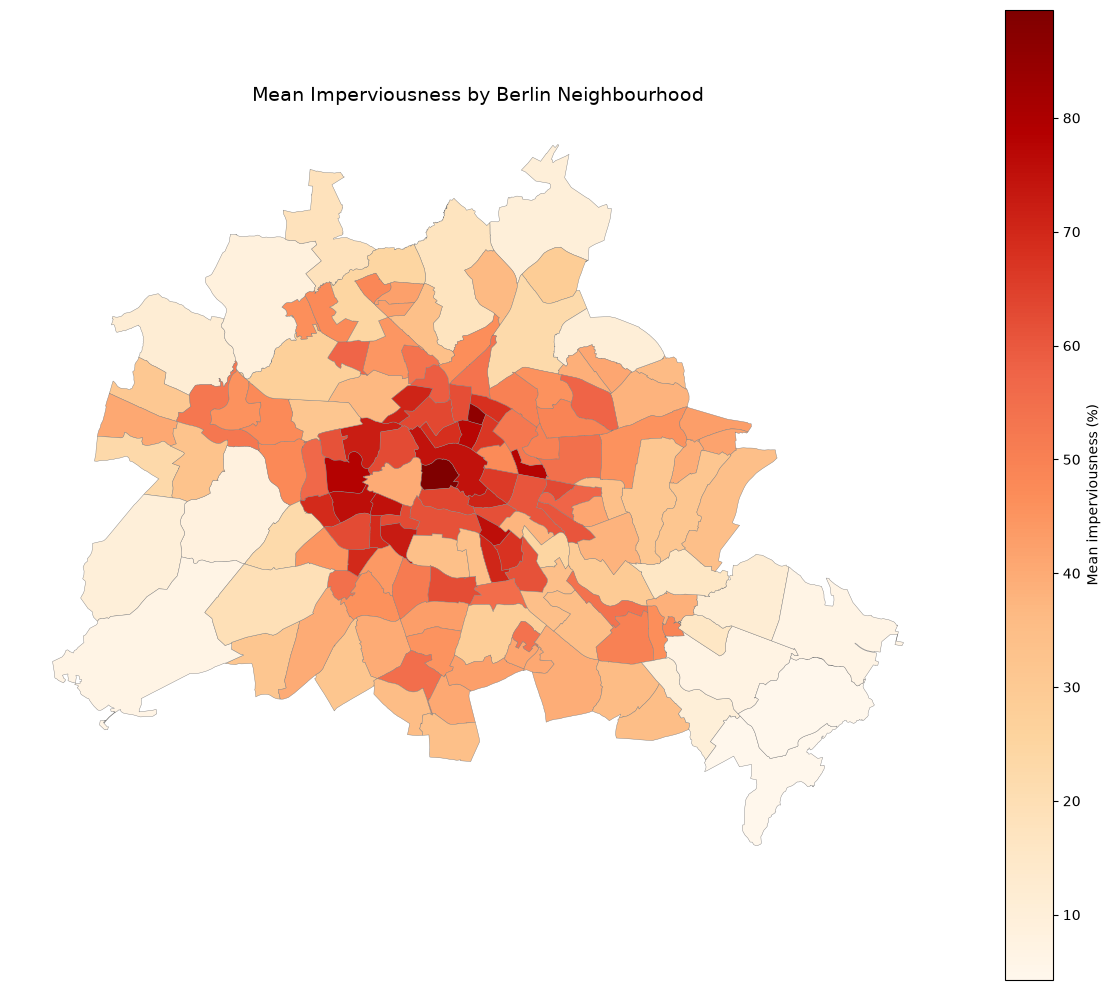

In [49]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

lor_land_cover_imperviousness.plot(
    column="imperviousness_mean",
    cmap="OrRd",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={
        "label": "Mean imperviousness (%)"
    },
    ax=ax
)

ax.set_title(
    "Mean Imperviousness by Berlin Neighbourhood",
    fontsize=14
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

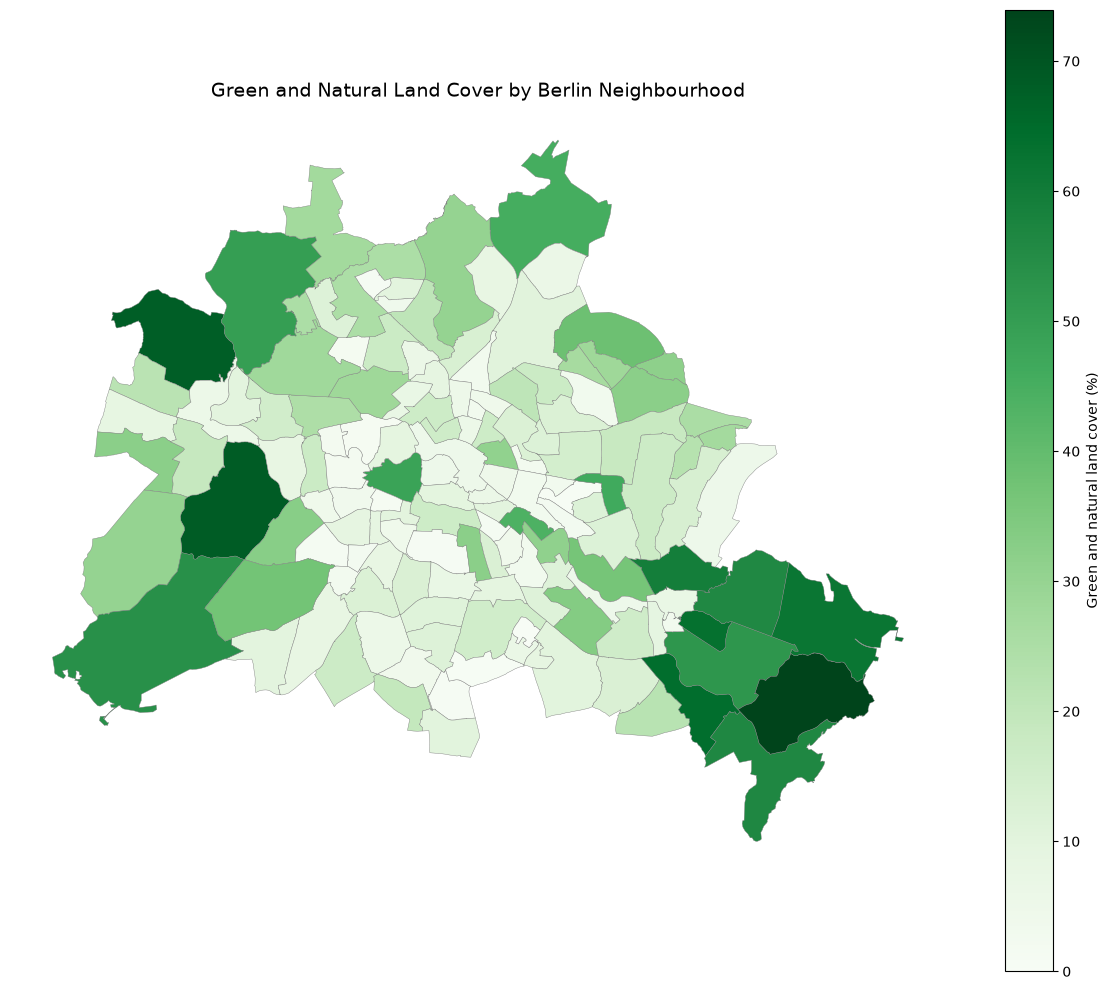

In [ ]:
# checking green areas percentage
fig, ax = plt.subplots(figsize=(12, 10))

lor_land_cover_imperviousness.plot(
    column="green_natural",
    cmap="Greens",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "Green and natural land cover (%)"},
    ax=ax
)

# Add title and remove axes
ax.set_title(
    "Green and Natural Land Cover by Berlin Neighbourhood",
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [52]:
# Calculate the correlation between the two indicators
correlation = lor_land_cover_imperviousness[
    ["green_natural", "imperviousness_mean"]
].corr()

print(correlation)

                     green_natural  imperviousness_mean
green_natural             1.000000            -0.758838
imperviousness_mean      -0.758838             1.000000


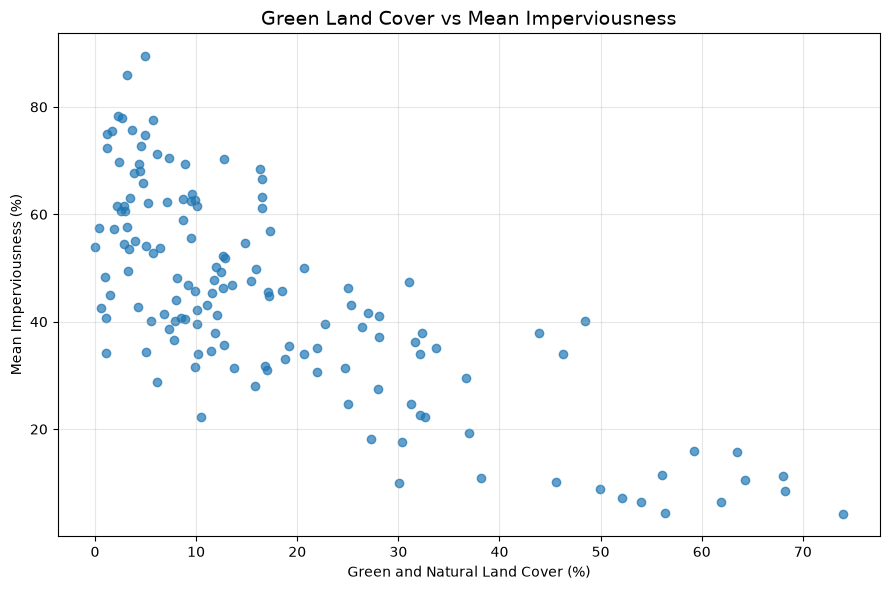

In [53]:
# Create a scatter plot
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    lor_land_cover_imperviousness["green_natural"],
    lor_land_cover_imperviousness["imperviousness_mean"],
    alpha=0.7
)

# Add labels
ax.set_title(
    "Green Land Cover vs Mean Imperviousness",
    fontsize=14
)
ax.set_xlabel("Green and Natural Land Cover (%)")
ax.set_ylabel("Mean Imperviousness (%)")

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
# Save the processed imperviousness indicators
imperviousness_by_lor.to_csv(
    "imperviousness_by_lor.csv",
    index=False
)